(sec-1)=
# 1. Trazabilidad de correcciones

(sec-1-1)=
## 1.1 Evaluación crítica del tercer entregable

Antes de proponer un modelo nuevo conviene preguntarse qué limitó a los 140 anteriores. La guía pide superar a los benchmarks, y eso solo tiene sentido si se entiende por qué ninguno de ellos se distinguió de los demás. Se revisan tres evidencias del tercer entregable: el desempeño por pliegue externo frente a la prevalencia de cada bloque (el AUC-PR de un clasificador aleatorio es igual a la prevalencia, así que su cociente, la **mejora sobre el azar**, es lo que mide la discriminación), el desempeño en la prueba y el efecto de la recalibración mensual del intercepto.

,Valida desde,Valida hasta,Prevalencia,Mejor AUC-PR (140 combinaciones),Mejora sobre el azar (mediana de finalistas),AUC máx. (finalistas)
Pliegue,,,,,,
1,2008-05,2008-06,"0,039","0,046","1,043","0,523"
2,2008-06,2008-07,"0,060","0,069","1,020","0,522"
3,2008-07,2008-08,"0,059","0,070","1,050","0,521"
4,2008-08,2008-11,"0,054","0,058","0,950","0,491"
5,2008-11,2009-05,"0,140","0,296","1,815","0,716"


Modelo,AUC-PR prueba,AUC prueba,AUC-PR con recalibración mensual,AUC con recalibración mensual
Naive Bayes · class_weight · Bayesiana (Optuna TPE),"0,534","0,714","0,478","0,677"
Logística L1/L2 · SMOTE · Random Search,"0,530","0,681","0,584","0,761"
Random Forest · Sin balanceo · Bayesiana (Optuna TPE),"0,503","0,720","0,541","0,742"
SVM · class_weight · Grid Search,"0,538","0,724",—,—
XGBoost · class_weight · Genético (DEAP),"0,369","0,559","0,482","0,721"
Árbol de decisión · SMOTE · Bayesiana (Optuna TPE),"0,374","0,567","0,423","0,615"
KNN · class_weight · Grid Search,"0,500","0,688","0,577","0,756"
"Referencia E2 (logística C = 0,01)","0,548","0,710","0,579","0,758"


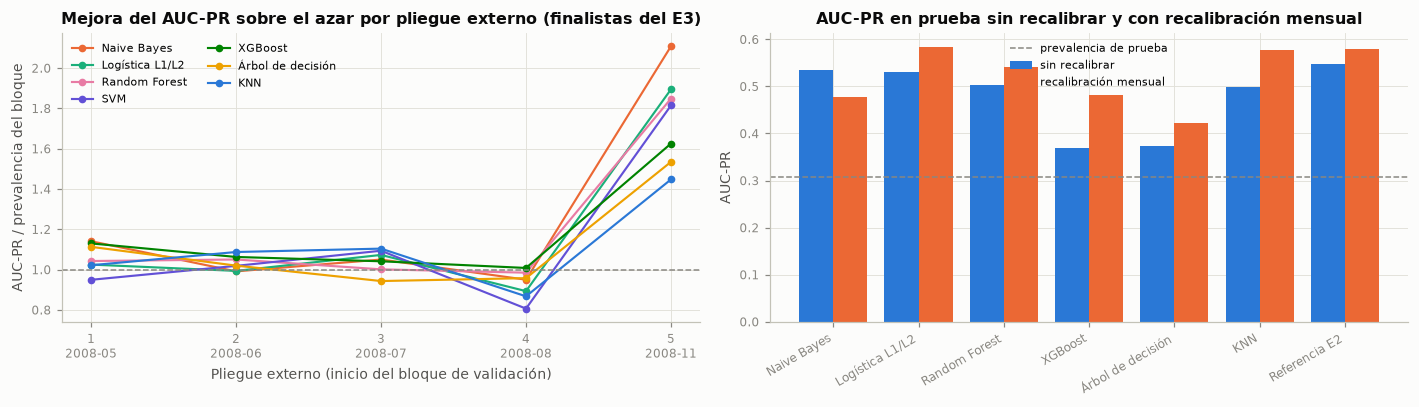

**Interpretación.** En 4 de los 4 primeros pliegues externos (validación dentro de 2008) la mediana de los finalistas apenas supera a la prevalencia (mejora sobre el azar entre 0,95 y 1,05), con AUC máximo de 0,523; solo el último pliegue, que valida de 2008-11 a 2009-05, muestra señal (mejora mediana de 1,81). En la prueba, el AUC-PR de los finalistas va de 0,369 a 0,548, y la recalibración mensual del intercepto lo sube en 6 de los 7 modelos con probabilidades (mediana de 0,049).

Esto significa que el ordenamiento de las 140 combinaciones lo decide casi por completo un solo bloque de validación, y que la mejora más grande del tercer entregable no vino de un modelo más flexible ni de una mejor búsqueda de hiperparámetros, sino de ajustar el intercepto a la tasa del mes que acaba de cerrar. Si desplazar un solo número por mes mejora el ordenamiento global más que cambiar de familia de modelos, la información que falta no está en las variables del cliente: está en el **momento** de la llamada, en un nivel de conversión que cambia con el tiempo y que un modelo estático no puede seguir.

Por tal motivo, se opta por dirigir el modelo original a ese vacío: en lugar de otro clasificador estático, un modelo que trate el nivel de conversión como un estado latente y lo actualice con las etiquetas que la operación genera cada día. La sección {ref}`2.2 <sec-2-2>` verifica con el entrenamiento que ese nivel existe y es persistente, y la sección 5 lo formaliza.

In [4]:
esquema = []
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
    esquema.append({"Pliegue": k_ + 1, "Valida desde": periodo_tr.iloc[i_v[0]], "Valida hasta": periodo_tr.iloc[i_v[-1]],
                    "Prevalencia": y_tr.iloc[i_v].mean()})
esquema = pd.DataFrame(esquema).set_index("Pliegue")
pl_clf = pliegues_e3[pliegues_e3["tarea"] == "clf"].copy()
pl_fin = pl_clf.merge(fin_ext[["modelo", "balanceo", "optimizador"]])
ap_fold = pl_fin.pivot_table(index="pliegue", columns="modelo", values="auc_pr")[MODELOS]
ap_fold.index = ap_fold.index + 1
mejora = ap_fold.div(esquema["Prevalencia"], axis=0)
diag = esquema.assign(**{"Mejor AUC-PR (140 combinaciones)": pl_clf.groupby("pliegue")["auc_pr"].max().to_numpy(),
                         "Mejora sobre el azar (mediana de finalistas)": mejora.median(axis=1),
                         "AUC máx. (finalistas)": pl_fin.groupby("pliegue")["auc"].max().to_numpy()})
tabla(diag, dec=3)

ult_mes = periodo_tr.iloc[-1]
m_ult = (periodo_tr == ult_mes).to_numpy()
filas = []
for k in MODELOS + ["referencia_e2"]:
    f_ = fin_e3[f"clf_{k}"]
    fila = {"Modelo": NOMBRE[k], "AUC-PR prueba": average_precision_score(yte, f_["puntaje_te"]),
            "AUC prueba": roc_auc_score(yte, f_["puntaje_te"])}
    if f_["es_proba"]:
        rec = evm.recalibracion_mensual(f_["puntaje_te"], yte, periodo_te.to_numpy(), f_["puntaje_tr"][m_ult],
                                        y_tr.to_numpy()[m_ult])
        fila.update({"AUC-PR con recalibración mensual": average_precision_score(yte, rec),
                     "AUC con recalibración mensual": roc_auc_score(yte, rec)})
    filas.append(fila)
diag_te = pd.DataFrame(filas)
tabla(diag_te, dec=3, indice=False)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for m in MODELOS:
    axs[0].plot(mejora.index, mejora[m], marker="o", ms=4, color=COLOR[m], lw=1.4, label=CORTO[m])
axs[0].axhline(1, color=GRIS, lw=1, ls="--")
axs[0].set_xticks(mejora.index, [f"{i}\n{esquema.loc[i, 'Valida desde']}" for i in mejora.index])
axs[0].set(title="Mejora del AUC-PR sobre el azar por pliegue externo (finalistas del E3)",
           ylabel="AUC-PR / prevalencia del bloque", xlabel="Pliegue externo (inicio del bloque de validación)")
axs[0].legend(ncol=2, fontsize=7)
d_ = diag_te.dropna()
xx = np.arange(len(d_))
axs[1].bar(xx - 0.2, d_["AUC-PR prueba"], 0.4, color=AZUL, label="sin recalibrar")
axs[1].bar(xx + 0.2, d_["AUC-PR con recalibración mensual"], 0.4, color=NARANJA, label="recalibración mensual")
axs[1].axhline(yte.mean(), color=GRIS, lw=1, ls="--", label="prevalencia de prueba")
axs[1].set_xticks(xx, [CORTO.get(k, k) for k in [m for m in MODELOS + ["referencia_e2"] if fin_e3[f"clf_{m}"]["es_proba"]]],
                  rotation=30, ha="right")
axs[1].set(title="AUC-PR en prueba sin recalibrar y con recalibración mensual", ylabel="AUC-PR")
axs[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

n_sin_senal = int((diag["Mejora sobre el azar (mediana de finalistas)"].iloc[:-1] < 1.15).sum())
ganancia_rec = (d_["AUC-PR con recalibración mensual"] - d_["AUC-PR prueba"])
interpretar(
    f"En {n_sin_senal} de los {len(diag) - 1} primeros pliegues externos (validación dentro de 2008) la mediana de los "
    f"finalistas apenas supera a la prevalencia (mejora sobre el azar entre "
    f"{num(diag['Mejora sobre el azar (mediana de finalistas)'].iloc[:-1].min(), 2)} y "
    f"{num(diag['Mejora sobre el azar (mediana de finalistas)'].iloc[:-1].max(), 2)}), con AUC máximo de "
    f"{num(diag['AUC máx. (finalistas)'].iloc[:-1].max(), 3)}; solo el último pliegue, que valida de "
    f"{esquema['Valida desde'].iloc[-1]} a {esquema['Valida hasta'].iloc[-1]}, muestra señal (mejora mediana de "
    f"{num(diag['Mejora sobre el azar (mediana de finalistas)'].iloc[-1], 2)}). En la prueba, el AUC-PR de los "
    f"finalistas va de {num(diag_te['AUC-PR prueba'].min(), 3)} a {num(diag_te['AUC-PR prueba'].max(), 3)}, y la "
    f"recalibración mensual del intercepto lo sube en {int((ganancia_rec > 0).sum())} de los {len(ganancia_rec)} "
    f"modelos con probabilidades (mediana de {num(ganancia_rec.median(), 3)}).",
    conectar("Esto significa que", "El ordenamiento de las 140 combinaciones lo decide casi por completo un solo bloque "
             "de validación, y que la mejora más grande del tercer entregable no vino de un modelo más flexible ni de "
             "una mejor búsqueda de hiperparámetros, sino de ajustar el intercepto a la tasa del mes que acaba de "
             "cerrar. Si desplazar un solo número por mes mejora el ordenamiento global más que cambiar de familia de "
             "modelos, la información que falta no está en las variables del cliente: está en el **momento** de la "
             "llamada, en un nivel de conversión que cambia con el tiempo y que un modelo estático no puede seguir."),
    conectar("Por tal motivo, se opta por", "Dirigir el modelo original a ese vacío: en lugar de otro clasificador "
             "estático, un modelo que trate el nivel de conversión como un estado latente y lo actualice con las "
             "etiquetas que la operación genera cada día. La sección 2.2 verifica con el entrenamiento que ese nivel "
             "existe y es persistente, y la sección 5 lo formaliza."))

### ¿Por qué ningún modelo más flexible supera a la logística?

En el Entregable 2 ningún modelo más flexible superó a la logística (sección 4.11) y en el tercero los finalistas de árboles quedaron por debajo de ella en la prueba. Un resultado así obliga a descartar un error del *pipeline* antes de interpretarlo. La prueba es simple: si el código estuviera mal, los modelos flexibles también perderían cuando no hay cambio de régimen. Se comparan la logística con C = 0,01, un Random Forest y un XGBoost con hiperparámetros fijos y razonables en tres escenarios: validación cruzada **aleatoria** dentro del entrenamiento (sin cambio de régimen), validación **temporal** (los cinco pliegues externos) y **prueba** (2009-2010). Además se mide qué parte de la prueba cae fuera del rango de las variables macroeconómicas vistas en el entrenamiento, porque un árbol no extrapola: fuera de ese rango su predicción es constante.

In [5]:
from sklearn.model_selection import StratifiedKFold
from bm.modelos import construir_pipeline


def modelos_flexibles():
    return {"Logística C = 0,01": construir_pipeline("clf", "logistica", "ninguno").set_params(
                modelo__C=0.01, modelo__l1_ratio=0.0, modelo__solver="lbfgs", modelo__max_iter=5000),
            "Random Forest": construir_pipeline("clf", "bosque", "ninguno").set_params(
                modelo__n_estimators=300, modelo__min_samples_leaf=20, modelo__n_jobs=8),
            "XGBoost": construir_pipeline("clf", "xgboost", "ninguno").set_params(
                modelo__n_estimators=300, modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_jobs=8)}


escenarios = {"aleatoria": StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, y_tr),
              "temporal": cv_externa(GAP).split(X_tr)}
escenarios = {k: list(v) for k, v in escenarios.items()}
filas = []
for nombre in modelos_flexibles():
    fila = {"Modelo": nombre}
    for esc, cortes in escenarios.items():
        s_auc, s_ap = [], []
        for i_e, i_v in cortes:
            m_ = modelos_flexibles()[nombre].fit(X_tr.iloc[i_e], y_tr.iloc[i_e])
            s_ = m_.predict_proba(X_tr.iloc[i_v])[:, 1]
            s_auc.append(roc_auc_score(y_tr.iloc[i_v], s_))
            s_ap.append(average_precision_score(y_tr.iloc[i_v], s_))
        fila[f"AUC {esc}"], fila[f"AUC-PR {esc}"] = np.mean(s_auc), np.mean(s_ap)
    s_ = modelos_flexibles()[nombre].fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fila["AUC prueba"], fila["AUC-PR prueba"] = roc_auc_score(y_te, s_), average_precision_score(y_te, s_)
    filas.append(fila)
flex = pd.DataFrame(filas).set_index("Modelo")
tabla(flex, dec=3)

rango = pd.DataFrame([{"Variable": c, "Mínimo entrenamiento": X_tr[c].min(), "Máximo entrenamiento": X_tr[c].max(),
                       "Mínimo prueba": X_te[c].min(), "Máximo prueba": X_te[c].max(),
                       "Prueba fuera del rango de entrenamiento": ((X_te[c] < X_tr[c].min()) | (X_te[c] > X_tr[c].max())).mean()}
                      for c in ("nr.employed", "cons.price.idx", "cons.conf.idx")])
tabla(rango, dec=3, indice=False)
(RES / "mejoras").mkdir(parents=True, exist_ok=True)
flex.to_parquet(RES / "mejoras" / "flexibles.parquet")
rango.to_parquet(RES / "mejoras" / "rango_macro.parquet", index=False)

base_f = flex.loc["Logística C = 0,01"]
mejor_alea = flex["AUC-PR aleatoria"].idxmax()
fuera_nr = rango.set_index("Variable").loc["nr.employed", "Prueba fuera del rango de entrenamiento"]
interpretar(
    f"Con validación aleatoria, el mejor AUC-PR es el de {mejor_alea} ({num(flex.loc[mejor_alea, 'AUC-PR aleatoria'], 3)}, "
    f"frente a {num(base_f['AUC-PR aleatoria'], 3)} de la logística); con validación temporal, los tres modelos quedan "
    f"entre {num(flex['AUC temporal'].min(), 3)} y {num(flex['AUC temporal'].max(), 3)} de AUC, y en la prueba la logística "
    f"obtiene el mayor AUC-PR ({num(base_f['AUC-PR prueba'], 3)}, frente a {num(flex['AUC-PR prueba'].drop(base_f.name).max(), 3)} "
    f"del mejor modelo flexible). El {pct(fuera_nr)} de los registros de prueba tiene un `nr.employed` por debajo del mínimo "
    f"visto en el entrenamiento ({num(X_tr['nr.employed'].min(), 1)}).",
    conectar("Esto significa que", "No hay un error en el *pipeline*: cuando el periodo de validación se parece al de "
             "ajuste, los modelos flexibles aprovechan las interacciones y superan a la logística, como se espera. Pierden "
             "su ventaja cuando el régimen cambia, porque aprendieron relaciones de 2008 que luego cambian (deriva de "
             "concepto) y porque un árbol no extrapola: con la mayoría de la prueba fuera del rango macroeconómico del "
             "entrenamiento, sus predicciones quedan planas donde la logística sigue la tendencia. El límite de este "
             "problema no es la forma funcional del modelo sino el cambio de régimen en el tiempo."),
    conectar("Por lo anterior, conviene", "Buscar la mejora en un modelo que trate el tiempo de forma explícita y no en "
             "un clasificador más flexible, que es la decisión que guía el modelo original de este entregable."))

,AUC aleatoria,AUC-PR aleatoria,AUC temporal,AUC-PR temporal,AUC prueba,AUC-PR prueba
Modelo,,,,,,
"Logística C = 0,01","0,667","0,190","0,517","0,098","0,705","0,543"
Random Forest,"0,669","0,207","0,517","0,087","0,716","0,497"
XGBoost,"0,672","0,203","0,533","0,090","0,642","0,449"


Variable,Mínimo entrenamiento,Máximo entrenamiento,Mínimo prueba,Máximo prueba,Prueba fuera del rango de entrenamiento
nr.employed,"5 099,100","5 228,100","4 963,600","5 099,100","0,602"
cons.price.idx,"92,756","94,465","92,201","94,767","0,306"
cons.conf.idx,"-50,000","-36,100","-50,800","-26,900","0,335"


**Interpretación.** Con validación aleatoria, el mejor AUC-PR es el de Random Forest (0,207, frente a 0,190 de la logística); con validación temporal, los tres modelos quedan entre 0,517 y 0,533 de AUC, y en la prueba la logística obtiene el mayor AUC-PR (0,543, frente a 0,497 del mejor modelo flexible). El 60,2 % de los registros de prueba tiene un `nr.employed` por debajo del mínimo visto en el entrenamiento (5 099,1).

Esto significa que no hay un error en el *pipeline*: cuando el periodo de validación se parece al de ajuste, los modelos flexibles aprovechan las interacciones y superan a la logística, como se espera. Pierden su ventaja cuando el régimen cambia, porque aprendieron relaciones de 2008 que luego cambian (deriva de concepto) y porque un árbol no extrapola: con la mayoría de la prueba fuera del rango macroeconómico del entrenamiento, sus predicciones quedan planas donde la logística sigue la tendencia. El límite de este problema no es la forma funcional del modelo sino el cambio de régimen en el tiempo.

Por lo anterior, conviene buscar la mejora en un modelo que trate el tiempo de forma explícita y no en un clasificador más flexible, que es la decisión que guía el modelo original de este entregable.

(sec-1-2)=
## 1.2 Tabla de trazabilidad de correcciones

La retroalimentación escrita del docente (nota de 4,8) señaló tres faltas y dos tareas para la siguiente entrega: *"Te resto porque no atendiste aún el cambio de prevalencia ni la inestabilidad de coeficientes con C = 100, y porque el componente temporal quedó parcial. Para la próxima entrega, recalibra el intercepto con datos recientes y compara modelos más flexibles."* La columna «Antes» resume cómo estaba cada punto en la versión calificada del Entregable 1 (cuaderno `Entregable 1 - Bank Marketing.ipynb`, incluido en esta carpeta). Las cinco quedaron resueltas desde el Entregable 2 (cuaderno `Entregable 2 - Bank Marketing.ipynb`, también incluido) y se mantienen en el tercero; este entregable las retoma como punto de partida del modelo original. Al valorar la interpretación, la misma retroalimentación anota además que *"el AUC de 0,677 es moderado, las probabilidades subestiman la prevalencia y el umbral elegido empeora en prueba"*; también quedaron resueltos en el Entregable 2, y la fila 6 documenta dónde y cómo se mantienen con el modelo de este entregable. La tabla separa cada observación en una fila, con la acción, la sección donde se resolvió y la evidencia que la respalda; la celda siguiente reproduce aquí la evidencia de las filas 1, 2 y 6. Al final se agregan los hallazgos de la evaluación crítica de la sección {ref}`1.1 <sec-1-1>`.

| N.º | Observación del docente | Antes: Entregable 1 (versión calificada con 4,8) | Acción realizada | Dónde se resolvió | Ubicación en este cuaderno (capítulo del libro) | Evidencia |
|---|---|---|---|---|---|---|
| 1 | No se atendió el cambio de prevalencia (6,4 % en entrenamiento frente a 30,8 % en prueba) | Probabilidad media en prueba de 0,243 frente a una tasa real de 0,308; la recalibración solo se anuncia para el siguiente entregable (sección 4.7) | Recalibración mensual del intercepto con los meses ya cerrados; en este entregable, el nivel de conversión se modela como estado latente y se filtra cada día | Entregable 2, sección 4.7.1; tercer entregable, sección 7.4 | Secciones {ref}`1.1 <sec-1-1>`, {ref}`1.2 <sec-1-2>`, {ref}`5.2 <sec-5-2>` y {ref}`6.6 <sec-6-6>` | Entregable 2: la probabilidad media en prueba pasa de 0,167 a 0,300 (tasa de 0,308), el error mensual baja de 22,8 a 8,5 puntos y el Brier de 0,206 a 0,178. Aquí: tabla de calibración mensual de la celda siguiente y Diebold-Mariano (sección {ref}`6.6 <sec-6-6>`) |
| 2 | Inestabilidad de los coeficientes con C = 100 | C = 100, elegido por el AUC de validación temporal (0,542), sin análisis de la estabilidad de los coeficientes (sección {ref}`4.1 <sec-4-1>`) | C elegido por pérdida logarítmica en validación temporal (C = 0,01) y estabilidad *bootstrap* de los coeficientes según C; en el L2E, λ se optimiza dentro de la validación anidada | Entregable 2, secciones 4.1 y 4.9.1; tercer entregable, modelo de referencia con C = 0,01 | Secciones {ref}`1.2 <sec-1-2>`, {ref}`5.8 <sec-5-8>` y {ref}`6.11 <sec-6-11>` | Entregable 2: pérdida logarítmica de validación de 0,2510 con C = 0,01 frente a 0,4947 con C = 100, y desviación *bootstrap* media de los coeficientes de 0,250 a 0,053. Aquí: estabilidad por pliegue en la celda siguiente y trayectorias de las pendientes (sección {ref}`6.11 <sec-6-11>`) |
| 3 | El componente temporal quedó parcial | Sección 3.6 marcada como de alcance parcial: solo contexto económico (3.6.1) y validación aleatoria frente a temporal (3.6.2), sin serie diaria, descomposición ni deriva de concepto | Serie diaria, cambios de régimen, descomposición, estacionariedad, dependencia temporal y deriva de concepto; evaluación de las variables de calendario y diagnóstico temporal por año y por residuos; en este entregable, el nivel diario latente como componente del modelo | Entregable 2, secciones 3.6.3, 3.6.4, 3.6.5, 4.9.2 y 4.10; tercer entregable, sección 3.6 | Secciones {ref}`2.2 <sec-2-2>` y {ref}`5.2 <sec-5-2>` | Entregable 2: AUC de 0,667 con validación aleatoria frente a 0,514 con validación temporal, y residuos autocorrelacionados (Ljung-Box, p < 0,001). Aquí: autocorrelación del logit diario y puntaje de solo nivel (sección {ref}`2.2 <sec-2-2>`) y trayectoria del nivel latente (sección {ref}`6.11 <sec-6-11>`) |
| 4 | Recalibrar el intercepto con datos recientes | Sin recalibración: AUC de prueba de 0,677 y AUC-PR de 0,489 con probabilidades sin ajustar (secciones {ref}`4.4 <sec-4-4>` y 4.7) | Recalibración mensual con el mes anterior cerrado, generalizada a todos los finalistas; en este entregable se demuestra que es un caso límite del filtro del L2E y se compara contra él | Entregable 2, sección 4.7.1; tercer entregable, sección 7.4 | Secciones {ref}`1.1 <sec-1-1>`, {ref}`5.4 <sec-5-4>` (propiedad P5) y 6.8 | Entregable 2: AUC de prueba de 0,710 a 0,752 con la recalibración mensual. Aquí: tabla de la sección {ref}`1.1 <sec-1-1>`, demostración P5 y controles con igual información (sección {ref}`6.8 <sec-6-8>`) |
| 5 | Comparar modelos más flexibles | Solo la regresión logística frente al Dummy (secciones {ref}`4.2 <sec-4-2>` y {ref}`4.4 <sec-4-4>`) | Splines, Random Forest y Gradient Boosting en el Entregable 2; 140 combinaciones (7 modelos, 4 balanceos y 4 optimizadores) en el tercer entregable; el L2E se compara contra los 7 finalistas | Entregable 2, sección 4.11; tercer entregable, secciones 5 a 8 | Secciones {ref}`3.1 <sec-3-1>` y 6 | Entregable 2: con la misma recalibración, AUC de prueba de 0,752 del modelo base frente a 0,751 (splines), 0,735 (Random Forest) y 0,697 (Gradient Boosting). Aquí: tabla de finalistas (sección {ref}`3.1 <sec-3-1>`) y pruebas de la sección 6 |
| 6 | AUC moderado, probabilidades que subestiman la prevalencia y umbral que empeora en prueba (anotados al valorar la interpretación) | AUC de prueba de 0,677 y AUC-PR de 0,489; probabilidad media de 0,243 frente a 0,308; el umbral de 0,60, elegido con el pliegue más reciente, baja el F1 de prueba de 0,428 (umbral 0,5) a 0,383 (secciones {ref}`4.3 <sec-4-3>` y {ref}`4.4 <sec-4-4>`) | Con C = 0,01 el umbral se vuelve a elegir con el pliegue más reciente y se recalcula sobre las probabilidades recalibradas; en este entregable, el L2E corrige el nivel cada día, de modo que sus probabilidades siguen la prevalencia y la misma regla de umbral del Entregable 1 (F1 máximo en el pliegue de validación más reciente, sin la prueba) se traslada a la prueba sin degradarse | Entregable 2, secciones 4.3, 4.4 y 4.7.1 | Secciones {ref}`1.2 <sec-1-2>`, {ref}`6.2 <sec-6-2>` y {ref}`6.6 <sec-6-6>` | Entregable 2: el umbral elegido (0,11) sube el F1 de prueba de 0,157 a 0,525; con la recalibración mensual, umbral de 0,13, F1 de 0,563 y AUC de 0,752, con probabilidad media de 0,300. Aquí: probabilidad media del L2E frente a la tasa observada y umbral elegido sin la prueba frente al óptimo a posteriori (celda siguiente); AUC de prueba en la tabla resumen (sección {ref}`6.2 <sec-6-2>`) |

**Hallazgos de la evaluación crítica del tercer entregable** (sección {ref}`1.1 <sec-1-1>`), atendidos en este entregable:

| N.º | Hallazgo | Acción realizada | Ubicación en este cuaderno | Evidencia |
|---|---|---|---|---|
| 7 | Friedman con cinco bloques no tiene potencia para separar modelos | Pruebas sobre bloques mensuales y semanales en orden temporal, *bootstrap* estacionario y permutación por días | Secciones {ref}`6.3 <sec-6-3>` a {ref}`6.7 <sec-6-7>` | Tablas de las secciones {ref}`6.3 <sec-6-3>` a {ref}`6.7 <sec-6-7>` |
| 8 | DeLong supone independencia, pero los registros de un mismo día comparten el nivel de conversión | DeLong se acompaña de *bootstrap* estacionario y permutación por días, y se verifica el supuesto | Sección {ref}`6.5 <sec-6-5>` | ANOVA por día y prueba de Ljung-Box (sección {ref}`6.5 <sec-6-5>`) |
| 9 | En 2008 ningún modelo discrimina y el ranking lo decide un solo pliegue | Se reporta el desempeño por pliegue y por mes, y se discute en qué periodos el modelo original no supera a los benchmarks | Secciones {ref}`1.1 <sec-1-1>`, {ref}`6.9 <sec-6-9>` y {ref}`8.3 <sec-8-3>` | Análisis de errores (sección {ref}`6.9 <sec-6-9>`) |

In [6]:
from bm.modelos import construir_pipeline

# Evidencia de la observación 2: estabilidad de los coeficientes entre los cinco pliegues externos
coefs = {"Logística C = 100 (Entregable 1)": [], "Logística C = 0,01 (corrección del Entregable 2)": [],
         "L2E (λ optimizado en cada pliegue)": []}
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
    for nombre, C_ in (("Logística C = 100 (Entregable 1)", 100.0),
                       ("Logística C = 0,01 (corrección del Entregable 2)", 0.01)):
        m_ = construir_pipeline("clf", "logistica", "ninguno").set_params(
            modelo__C=C_, modelo__l1_ratio=0.0, modelo__solver="lbfgs", modelo__max_iter=5000, modelo__tol=1e-4)
        m_.fit(X_tr.iloc[i_e], y_tr.iloc[i_e])
        coefs[nombre].append(pd.Series(m_.named_steps["modelo"].coef_.ravel(),
                                       index=m_.named_steps["pre"].get_feature_names_out()))
    p_ = {k.split("__")[1]: v for k, v in corr["l2e"][k_]["params"].items()}
    m_ = construir_pipeline_original("l2e", **p_).fit(con_dia(X_tr.iloc[i_e], tiempo_tr.iloc[i_e]), y_tr.iloc[i_e])
    coefs["L2E (λ optimizado en cada pliegue)"].append(pd.Series(m_[-1].coef_, index=m_[:-1].get_feature_names_out()[:-1]))
estab = []
for nombre, lista in coefs.items():
    D_ = pd.concat(lista, axis=1).dropna()
    estab.append({"Modelo": nombre, "Coeficientes comunes a los 5 pliegues": len(D_),
                  "Desviación estándar mediana entre pliegues": D_.std(axis=1).median(),
                  "Desviación estándar máxima": D_.std(axis=1).max(), "|Coeficiente| máximo": D_.abs().max().max()})
estab = pd.DataFrame(estab)
tabla(estab, dec=3, indice=False)

# Evidencia de la observación 1: probabilidad media frente a la tasa observada en cada mes de la prueba
ref_ = fin_e3["clf_referencia_e2"]
m_ult = (periodo_tr == periodo_tr.iloc[-1]).to_numpy()
cal_mes = pd.DataFrame({"periodo": periodo_te.to_numpy(), "y": yte, "Referencia E2 sin recalibrar": ref_["puntaje_te"],
                        "Referencia E2 con recalibración mensual": evm.recalibracion_mensual(
                            ref_["puntaje_te"], yte, periodo_te.to_numpy(), ref_["puntaje_tr"][m_ult], y_tr.to_numpy()[m_ult]),
                        "L2E": PUNTAJE_TE["L2E"]}).groupby("periodo").mean()
err_mes = cal_mes.drop(columns="y").sub(cal_mes["y"], axis=0).abs()
resumen_cal = pd.DataFrame({"Error absoluto medio mensual (prob. media − tasa)": err_mes.mean(),
                            "Error máximo mensual": err_mes.max(),
                            "Probabilidad media en prueba": cal_mes.drop(columns="y").mul(
                                pd.Series(periodo_te).value_counts().reindex(cal_mes.index), axis=0).sum() / len(yte)})
tabla(resumen_cal, dec=3)
print(f"Tasa observada en prueba: {num(yte.mean(), 3)}")

# Evidencia de la observación 6: la regla de umbral del Entregable 1 (F1 máximo en el pliegue de validación más
# reciente, sin la prueba) aplicada a las predicciones precuenciales del L2E
from sklearn.metrics import f1_score

oof_ = corr["l2e"][cfg.K_EXTERNO - 1]["oof"]
rejilla_u = np.round(np.arange(0.05, 0.951, 0.01), 2)
u_val = rejilla_u[np.argmax([f1_score(oof_["y"], np.asarray(oof_["puntaje"]) >= u) for u in rejilla_u])]
f1_te = {u: f1_score(yte, PUNTAJE_TE["L2E"] >= u) for u in rejilla_u}
u_opt = max(f1_te, key=f1_te.get)
umbrales = pd.DataFrame({"Umbral": [0.5, u_val, u_opt],
                         "F1 en prueba": [f1_score(yte, PUNTAJE_TE["L2E"] >= 0.5), f1_te[u_val], f1_te[u_opt]]},
                        index=["Umbral fijo de 0,5", "Elegido sin la prueba (regla del Entregable 1)",
                               "Óptimo a posteriori en la prueba (solo referencia)"])
tabla(umbrales, dec=3)
para_guion("correcciones", {
    "de_c100": estab.iloc[0]["Desviación estándar mediana entre pliegues"],
    "de_c001": estab.iloc[1]["Desviación estándar mediana entre pliegues"],
    "de_l2e": estab.iloc[2]["Desviación estándar mediana entre pliegues"],
    "err_sin": resumen_cal.iloc[0, 0], "err_rec": resumen_cal.iloc[1, 0], "err_l2e": resumen_cal.iloc[2, 0],
    "prob_l2e": resumen_cal.iloc[2, 2], "tasa": yte.mean(), "lam": L2E["params"]["modelo__lam"],
    "u_val": u_val, "f1_val": umbrales.iloc[1, 1], "f1_05": umbrales.iloc[0, 1], "u_opt": u_opt,
    "f1_opt": umbrales.iloc[2, 1]})

e_ = estab.set_index("Modelo")["Desviación estándar mediana entre pliegues"]
interpretar(
    f"Entre los cinco pliegues externos, la desviación estándar mediana de los coeficientes es de {num(e_.iloc[0], 3)} con "
    f"C = 100 y de {num(e_.iloc[1], 3)} con C = 0,01, es decir, {num(e_.iloc[0] / e_.iloc[1], 1)} veces menor, y el "
    f"coeficiente más grande pasa de {num(estab.iloc[0]['|Coeficiente| máximo'], 2)} a "
    f"{num(estab.iloc[1]['|Coeficiente| máximo'], 2)}; el L2E queda en {num(e_.iloc[2], 3)}. En la prueba, la probabilidad "
    f"media de la referencia sin recalibrar se aleja de la tasa de cada mes en {num(resumen_cal.iloc[0, 0], 3)} en promedio; "
    f"con la recalibración mensual, en {num(resumen_cal.iloc[1, 0], 3)}, y con el L2E, en {num(resumen_cal.iloc[2, 0], 3)}. "
    "La cifra de la recalibración difiere de los 8,5 puntos del Entregable 2 porque allí el desplazamiento se estima "
    "con el mes anterior y, si tiene menos de 500 contactos, con los previos hasta reunirlos, mientras que aquí se usa "
    "la versión del tercer entregable, que toma solo el mes inmediatamente anterior. La probabilidad media del L2E en "
    f"la prueba es de {num(resumen_cal.iloc[2, 2], 3)}, frente a una tasa observada de {num(yte.mean(), 3)} (en el "
    "Entregable 1 era de 0,243). Con la misma regla de umbral del Entregable 1, el pliegue externo más reciente elige "
    f"un umbral de {num(u_val, 2)}, que en la prueba da un F1 de {num(umbrales.iloc[1, 1], 3)}, frente a "
    f"{num(umbrales.iloc[0, 1], 3)} con 0,5 y {num(umbrales.iloc[2, 1], 3)} con el óptimo a posteriori "
    f"({num(u_opt, 2)}); en el Entregable 1, el umbral elegido bajaba el F1 de 0,428 a 0,383, y desde el Entregable 2 "
    "lo sube (de 0,157 a 0,525).",
    conectar("Esto significa que", "Las correcciones que pidió el docente se sostienen con los datos de "
             "este entregable: la regularización elegida por pérdida logarítmica estabiliza los coeficientes, y la "
             "recalibración con datos recientes reduce el desfase de prevalencia, que el L2E corrige además día a día. "
             "Como las probabilidades del L2E siguen la prevalencia, un umbral elegido con el pasado conserva su sentido "
             "en la prueba, que era lo que fallaba en el Entregable 1, donde el umbral se aprendía con una prevalencia "
             "que ya no era la del periodo siguiente. Hay "
             "que tener en cuenta que el L2E es menos estable que la logística con C = 0,01 entre pliegues, porque Optuna "
             "elige un λ distinto en cada uno (sección 5.8) y en algunos la penalización es débil; el modelo final usa "
             f"λ = {num_c(L2E['params']['modelo__lam'])}, del mismo orden que C = 0,01."),
    conectar("Por tal motivo, se opta por", "Dar por resueltas las observaciones del docente, con la evidencia de "
             "esta celda y de las secciones indicadas en la tabla, y declarar la menor estabilidad del L2E entre pliegues "
             "como una limitación (sección 8.3)."))

Modelo,Coeficientes comunes a los 5 pliegues,Desviación estándar mediana entre pliegues,Desviación estándar máxima,|Coeficiente| máximo
Logística C = 100 (Entregable 1),37,"0,144","0,635","1,529"
"Logística C = 0,01 (corrección del Entregable 2)",37,"0,023","0,063","0,152"
L2E (λ optimizado en cada pliegue),37,"0,092","0,364","0,846"


,Error absoluto medio mensual (prob. media − tasa),Error máximo mensual,Probabilidad media en prueba
Referencia E2 sin recalibrar,"0,228","0,394","0,167"
Referencia E2 con recalibración mensual,"0,102","0,217","0,288"
L2E,"0,015","0,047","0,308"


Tasa observada en prueba: 0,308


,Umbral,F1 en prueba
"Umbral fijo de 0,5","0,500","0,504"
Elegido sin la prueba (regla del Entregable 1),"0,230","0,587"
Óptimo a posteriori en la prueba (solo referencia),"0,260","0,588"


**Interpretación.** Entre los cinco pliegues externos, la desviación estándar mediana de los coeficientes es de 0,144 con C = 100 y de 0,023 con C = 0,01, es decir, 6,3 veces menor, y el coeficiente más grande pasa de 1,53 a 0,15; el L2E queda en 0,092. En la prueba, la probabilidad media de la referencia sin recalibrar se aleja de la tasa de cada mes en 0,228 en promedio; con la recalibración mensual, en 0,102, y con el L2E, en 0,015. La cifra de la recalibración difiere de los 8,5 puntos del Entregable 2 porque allí el desplazamiento se estima con el mes anterior y, si tiene menos de 500 contactos, con los previos hasta reunirlos, mientras que aquí se usa la versión del tercer entregable, que toma solo el mes inmediatamente anterior. La probabilidad media del L2E en la prueba es de 0,308, frente a una tasa observada de 0,308 (en el Entregable 1 era de 0,243). Con la misma regla de umbral del Entregable 1, el pliegue externo más reciente elige un umbral de 0,23, que en la prueba da un F1 de 0,587, frente a 0,504 con 0,5 y 0,588 con el óptimo a posteriori (0,26); en el Entregable 1, el umbral elegido bajaba el F1 de 0,428 a 0,383, y desde el Entregable 2 lo sube (de 0,157 a 0,525).

Esto significa que las correcciones que pidió el docente se sostienen con los datos de este entregable: la regularización elegida por pérdida logarítmica estabiliza los coeficientes, y la recalibración con datos recientes reduce el desfase de prevalencia, que el L2E corrige además día a día. Como las probabilidades del L2E siguen la prevalencia, un umbral elegido con el pasado conserva su sentido en la prueba, que era lo que fallaba en el Entregable 1, donde el umbral se aprendía con una prevalencia que ya no era la del periodo siguiente. Hay que tener en cuenta que el L2E es menos estable que la logística con C = 0,01 entre pliegues, porque Optuna elige un λ distinto en cada uno (sección {ref}`5.8 <sec-5-8>`) y en algunos la penalización es débil; el modelo final usa λ = 63,8, del mismo orden que C = 0,01.

Por tal motivo, se opta por dar por resueltas las observaciones del docente, con la evidencia de esta celda y de las secciones indicadas en la tabla, y declarar la menor estabilidad del L2E entre pliegues como una limitación (sección {ref}`8.3 <sec-8-3>`).